# 3. Metodología de análisis de datos con IA

## Algortimos de aprendizaje clásico: Decision Tree

In [1]:
# Importar librerías
from copy import deepcopy
import pandas as pd
# Importar Decision Tree de scikit-learn
from sklearn import tree
# Importar objeto para k-fold cross-validation con grid de hyperparámetros
from sklearn.model_selection import GridSearchCV
# Importar objeto para separación de datos en conjuntos de entrenamiento y evaluación
from sklearn.model_selection import train_test_split
# Importar objeto para escalamiento de datos
from sklearn.preprocessing import StandardScaler
# Importar metricas de evaluación
from sklearn.metrics import f1_score, precision_score, recall_score, roc_auc_score, roc_curve
# Importar objeto para imprimir matriz de confusión
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
# Importar objeto para imprimir reporte de clasificación
from sklearn.metrics import classification_report
# Plots
import matplotlib.pyplot as plt 



## 1. Leer conjunto de datos
Origen y descripción de conjunto de datos en:
https://archive.ics.uci.edu/ml/datasets/Heart+failure+clinical+records

In [64]:
data_set = pd.read_csv("/mnt/c/Users/vrahu/Documents/Ismadlsh/CCG/2026-S5/Data_Science/data/heart_failure_clinical_records_dataset.csv")
data_set.head(6)

,age,anaemia,creatinine_phosphokinase,diabetes,ejection_fraction,high_blood_pressure,platelets,serum_creatinine,serum_sodium,sex,smoking,time,DEATH_EVENT
0,75.0,0,582,0,20,1,265000.00,1.9,130,1,0,4,1
1,55.0,0,7861,0,38,0,263358.03,1.1,136,1,0,6,1
2,65.0,0,146,0,20,0,162000.00,1.3,129,1,1,7,1
3,50.0,1,111,0,20,0,210000.00,1.9,137,1,0,7,1
4,65.0,1,160,1,20,0,327000.00,2.7,116,0,0,8,1
5,90.0,1,47,0,40,1,204000.00,2.1,132,1,1,8,1


### Verificar dimensionalidad de datos

In [65]:
print("Dimensionalidad del data set")
data_set.shape

Dimensionalidad del data set


(299, 13)

### Verificar categorías de clase

In [66]:
print("Categorías únicas de clasificación")
data_set['DEATH_EVENT'].unique()

Categorías únicas de clasificación


array([1, 0])

### Verificar cuántos ejemplos hay por categoría, verificar si existe desbalance de datos

In [67]:
print("Ejemplos por categoría")
print(data_set.groupby('DEATH_EVENT').size())

Ejemplos por categoría
DEATH_EVENT
0    203
1     96
dtype: int64


## 2. Preparación de datos
### 2.1 Separación de características y categorías de clase

*   Guardar en X sólo características
*   Guardar en y sólo categorías de clase


Guardar

In [68]:
X = data_set.iloc[:,0:11]  # todos los renglones y las columnas de la 0 a la 11
print("Características")
print(X.head())

Características
    age  anaemia  creatinine_phosphokinase  diabetes  ejection_fraction  high_blood_pressure  platelets  serum_creatinine  serum_sodium  sex  smoking
0  75.0        0                       582         0                 20                    1  265000.00               1.9           130    1        0
1  55.0        0                      7861         0                 38                    0  263358.03               1.1           136    1        0
2  65.0        0                       146         0                 20                    0  162000.00               1.3           129    1        1
3  50.0        1                       111         0                 20                    0  210000.00               1.9           137    1        0
4  65.0        1                       160         1                 20                    0  327000.00               2.7           116    0        0


In [69]:
y = data_set.iloc[:, 12]  # todos los renglones y sólo la columna 12
print("Categorias de clase")
print(y.head())

Categorias de clase
0    1
1    1
2    1
3    1
4    1
Name: DEATH_EVENT, dtype: int64


In [70]:
value_counts = y.value_counts()
print(value_counts)

DEATH_EVENT
0    203
1     96
Name: count, dtype: int64


In [71]:
#resultados con y sin escalamiento de datos 
res_dic={
    "metrics":["hiper_parameters",
        "F1_train","F1_test","precision","recall","roc_auc","macro_F1_test", 
        "macro_precision","macro_recall",
        "weighted_F1_test","weighted_precision","weighted_recall"],
    "scaled":[],
    "unscaled":[]
}

### 2.2 Escalamiento de características

*   Guardamos en X las características escaladas



In [72]:
scaler = StandardScaler()
scaler.fit(X)
X_scaled = scaler.transform(X)

data_set_T={
    "scaled":{
        "X":X,
        "X_train":None,
        "y_train":None,
        "X_test":None,
        "y_test":None
    },
    "unscaled":{
        "X":X_scaled,
        "X_train":None,
        "y_train":None,
        "X_test":None,
        "y_test":None
    }
}
print("Características escaladas")
print(X)
print(X_scaled)

Características escaladas
      age  anaemia  creatinine_phosphokinase  diabetes  ejection_fraction  high_blood_pressure  platelets  serum_creatinine  serum_sodium  sex  smoking
0    75.0        0                       582         0                 20                    1  265000.00               1.9           130    1        0
1    55.0        0                      7861         0                 38                    0  263358.03               1.1           136    1        0
2    65.0        0                       146         0                 20                    0  162000.00               1.3           129    1        1
3    50.0        1                       111         0                 20                    0  210000.00               1.9           137    1        0
4    65.0        1                       160         1                 20                    0  327000.00               2.7           116    0        0
..    ...      ...                       ...       ...        

### 2.3 Separación de datos en conjuntos de entrenamiento (tran) y prueba (test)
* Usamos función train_test_split() 

Esto para hacer la separación de manera estratificada con el objetivo de conservar las mismas proporciones de nuestra varaible calsificatoria y 96 a 203 

In [74]:

#fijar un random state para reproducibilida
random_state = 42

for data_t in data_set_T.keys():
    print(f"Separando datos de {data_t}")
    data_set_T[data_t]["X_train"], data_set_T[data_t]["X_test"], data_set_T[data_t]["y_train"], data_set_T[data_t]["y_test"] = train_test_split(data_set_T[data_t]["X"], y, test_size=0.2, random_state=random_state, stratify=y)

Separando datos de scaled
Separando datos de unscaled


* Exploramos conjunto de datos de entrenamiento y categorías

In [75]:

for data_t in data_set_T.keys():
    print(f"Dimensionalidad de datos de entrenamiento {data_t}")
    print(data_set_T[data_t]["X_train"].shape)
    print("Dimensionalidad de categorías de entrenamiento")
    print(data_set_T[data_t]["y_train"].shape)
    print("Ejemplos de entrenamiento por categoría")
    print(data_set_T[data_t]["y_train"].value_counts())


Dimensionalidad de datos de entrenamiento scaled
(239, 11)
Dimensionalidad de categorías de entrenamiento
(239,)
Ejemplos de entrenamiento por categoría
DEATH_EVENT
0    162
1     77
Name: count, dtype: int64
Dimensionalidad de datos de entrenamiento unscaled
(239, 11)
Dimensionalidad de categorías de entrenamiento
(239,)
Ejemplos de entrenamiento por categoría
DEATH_EVENT
0    162
1     77
Name: count, dtype: int64


* Exploramos conjunto de datos de prueba y categorías

In [76]:
for data_t in data_set_T.keys():
    print(f"Dimensionalidad de datos de prueba en {data_t}")
    print(data_set_T[data_t]["X_test"].shape)
    print("Dimensionalidad de categorías de entrenamiento")
    print(data_set_T[data_t]["y_test"].shape)
    print("Ejemplos de entrenamiento por categoría")
    print(data_set_T[data_t]["y_test"].value_counts())

Dimensionalidad de datos de prueba en scaled
(60, 11)
Dimensionalidad de categorías de entrenamiento
(60,)
Ejemplos de entrenamiento por categoría
DEATH_EVENT
0    41
1    19
Name: count, dtype: int64
Dimensionalidad de datos de prueba en unscaled
(60, 11)
Dimensionalidad de categorías de entrenamiento
(60,)
Ejemplos de entrenamiento por categoría
DEATH_EVENT
0    41
1    19
Name: count, dtype: int64


## 3. Creación del modelo

### 3.1 Creación de objeto usando algortimo tree (decision tree)

In [77]:
algoritmo_dt = tree.DecisionTreeClassifier()

3.2 Definición de grid de hiperparámetros

In [78]:
hiperparameters = {'criterion':('gini', 'entropy'), 'class_weight':['balanced', None]}

El elegir más de un hiperparametro se crea una "grid" de hiperparametros en la que se crean modelos de la permutación de hiperparametros, que son todas las combinaciones sin repetición. 

El siguiente paso es testear los modelos generados por las combianciones de los hiperparametros, para saber como se entrenaran los modelos, y como se evaluaran, por ejemplo mediante `GridSearchCV` se asigna la metrica a evaluar y el cross validation para la division del dataset de entrenamiento y obtener la metrica global de cada configuración. 

In [79]:
tree_model = GridSearchCV(algoritmo_dt, hiperparameters, verbose=2, scoring="f1_macro", cv=5)

In [82]:
for data_t in data_set_T.keys():
    print(f"Entrenando modelo de árbol de decisión con datos {data_t}")
    X_train = data_set_T[data_t]["X_train"]
    y_train = data_set_T[data_t]["y_train"]
    tree_t= deepcopy(tree_model)
    data_set_T[data_t]["tree_model"]= tree_t
    data_set_T[data_t]["tree_model"] = tree_t.fit(X_train, y_train)

Entrenando modelo de árbol de decisión con datos scaled
Fitting 5 folds for each of 4 candidates, totalling 20 fits
[CV] END ..............class_weight=balanced, criterion=gini; total time=   0.0s
[CV] END ..............class_weight=balanced, criterion=gini; total time=   0.0s
[CV] END ..............class_weight=balanced, criterion=gini; total time=   0.0s
[CV] END ..............class_weight=balanced, criterion=gini; total time=   0.0s
[CV] END ..............class_weight=balanced, criterion=gini; total time=   0.0s
[CV] END ...........class_weight=balanced, criterion=entropy; total time=   0.0s
[CV] END ...........class_weight=balanced, criterion=entropy; total time=   0.0s
[CV] END ...........class_weight=balanced, criterion=entropy; total time=   0.0s
[CV] END ...........class_weight=balanced, criterion=entropy; total time=   0.0s
[CV] END ...........class_weight=balanced, criterion=entropy; total time=   0.0s
[CV] END ..................class_weight=None, criterion=gini; total time= 

### 3.4 Obtenemos mejor métrica y mejores hiperparámetros del mejor modelo

In [83]:
for data_t in data_set_T.keys():
    tree_t=data_set_T[data_t]["tree_model"]
    print(f"Resultados de entrenamiento con datos {data_t}")
    print("Mejores hyperparámetros")
    print(tree_t.best_params_)
    res_dic[data_t].append(tree_t.best_params_)
    print("Mejor F-1 macro score")
    print(tree_t.best_score_)
    res_dic[data_t].append(tree_t.best_score_)

Resultados de entrenamiento con datos scaled
Mejores hyperparámetros
{'class_weight': 'balanced', 'criterion': 'entropy'}
Mejor F-1 macro score
0.6346507972314424
Resultados de entrenamiento con datos unscaled
Mejores hyperparámetros
{'class_weight': 'balanced', 'criterion': 'gini'}
Mejor F-1 macro score
0.6503207436388612


## 4. Prueba del modelo (evaluación)
### 4.1 Predicción con datos de prueba y obtención de métricas
* La variable y_pred guardará las predicciones del modelo

In [84]:
for data_t in data_set_T.keys():
    print(f"Evaluando modelo de árbol de decisión con datos {data_t}")
    X_test = data_set_T[data_t]["X_test"]
    y_test = data_set_T[data_t]["y_test"]
    tree_t=data_set_T[data_t]["tree_model"]
    #hacer la predicción 
    y_pred = tree_t.predict(X_test)
    data_set_T[data_t]["y_pred"] = y_pred
    print(f"Resultados en la fase de prueba en {data_t}")
    #add the f1_score
    f_1=f1_score(y_test, y_pred)
    res_dic[data_t].append(f_1)
    print(f"F-1 score: {f_1}")
    #add the precision
    precision=precision_score(y_test, y_pred)
    res_dic[data_t].append(precision)
    print(f"Precision: {precision}")
    #add the recal 
    recall=recall_score(y_test, y_pred)
    res_dic[data_t].append(recall)
    print(f"Recall: {recall}")
    #add the roc_auc_score
    roc_auc=roc_auc_score(y_test, y_pred)
    res_dic[data_t].append(roc_auc)
    print(f"AUROC: {roc_auc}")


Evaluando modelo de árbol de decisión con datos scaled
Resultados en la fase de prueba en scaled
F-1 score: 0.5789473684210527
Precision: 0.5789473684210527
Recall: 0.5789473684210527
AUROC: 0.6919127086007704
Evaluando modelo de árbol de decisión con datos unscaled
Resultados en la fase de prueba en unscaled
F-1 score: 0.5909090909090909
Precision: 0.52
Recall: 0.6842105263157895
AUROC: 0.6957637997432605


### 4.2 Matriz de confusión

Tree confusion matrix de scaled:
[[33  8]
 [ 8 11]]
Tree confusion matrix (norm) de scaled:
[[0.80487805 0.19512195]
 [0.42105263 0.57894737]]
Tree confusion matrix de unscaled:
[[29 12]
 [ 6 13]]
Tree confusion matrix (norm) de unscaled:
[[0.70731707 0.29268293]
 [0.31578947 0.68421053]]


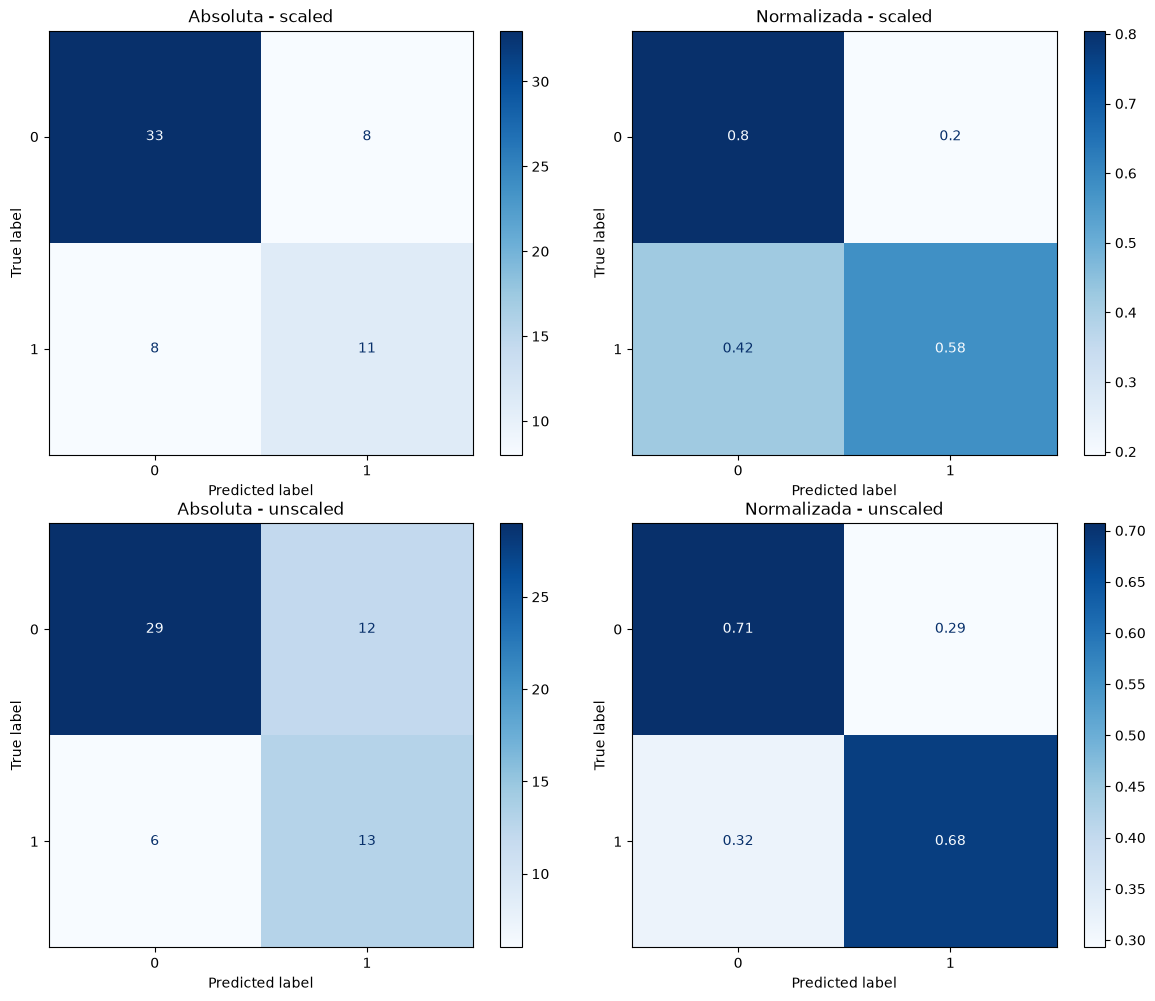

In [96]:
fig, ax = plt.subplots(2, 2, figsize=(12, 10))
# Aplanamos el arreglo de 2x2 a 1D (índices 0, 1, 2, 3) para iterar fácilmente
axes = ax.flatten() 

plot_idx = 0 # Usaremos este contador manual para los ejes

for data_t in data_set_T.keys():
    
    y_pred = data_set_T[data_t]["y_pred"]
    y_test = data_set_T[data_t]["y_test"]
    tree_t = data_set_T[data_t]["tree_model"]
    
    # 1. Gráfica de matriz sin normalizar
    tree_confusion_matrix = confusion_matrix(y_test, y_pred)
    print(f"Tree confusion matrix de {data_t}:\n{tree_confusion_matrix}")
    
    disp = ConfusionMatrixDisplay(confusion_matrix=tree_confusion_matrix,
                                  display_labels=tree_t.classes_)
    disp.plot(cmap=plt.cm.Blues, ax=axes[plot_idx])
    axes[plot_idx].set_title(f"Absoluta - {data_t}")
    plot_idx += 1 # Avanzamos al siguiente subplot
    
    # 2. Gráfica de matriz normalizada
    tree_confusion_matrix_norm = confusion_matrix(y_test, y_pred, normalize='true')
    print(f"Tree confusion matrix (norm) de {data_t}:\n{tree_confusion_matrix_norm}")
    
    disp_norm = ConfusionMatrixDisplay(confusion_matrix=tree_confusion_matrix_norm,
                                       display_labels=tree_t.classes_)
    disp_norm.plot(cmap=plt.cm.Blues, ax=axes[plot_idx])
    axes[plot_idx].set_title(f"Normalizada - {data_t}")
    plot_idx += 1 # Avanzamos al siguiente subplot

# Ajusta el espaciado para que los textos no se encimen
plt.tight_layout()
plt.show() 

fig.savefig("/mnt/c/Users/vrahu/Documents/Ismadlsh/CCG/2026-S5/Data_Science/res/heart_failure_DT_vGrid.png", dpi=300, bbox_inches='tight')

### 4.3 Reporte de clasificación

In [87]:
for data_t in data_set_T.keys():
    y_pred = data_set_T[data_t]["y_pred"]
    y_test = data_set_T[data_t]["y_test"]
    report_class=classification_report(y_test, y_pred, output_dict=True)
    res_dic[data_t].append(report_class["macro avg"]["f1-score"])
    res_dic[data_t].append(report_class["macro avg"]["precision"])
    res_dic[data_t].append(report_class["macro avg"]["recall"])
    res_dic[data_t].append(report_class["weighted avg"]["f1-score"])
    res_dic[data_t].append(report_class["weighted avg"]["precision"])
    res_dic[data_t].append(report_class["weighted avg"]["recall"])
    print(type(report_class))
    print(report_class)
    print(classification_report(y_test, y_pred))


<class 'dict'>
{'0': {'precision': 0.8048780487804879, 'recall': 0.8048780487804879, 'f1-score': 0.8048780487804879, 'support': 41.0}, '1': {'precision': 0.5789473684210527, 'recall': 0.5789473684210527, 'f1-score': 0.5789473684210527, 'support': 19.0}, 'accuracy': 0.7333333333333333, 'macro avg': {'precision': 0.6919127086007703, 'recall': 0.6919127086007703, 'f1-score': 0.6919127086007703, 'support': 60.0}, 'weighted avg': {'precision': 0.7333333333333333, 'recall': 0.7333333333333333, 'f1-score': 0.7333333333333333, 'support': 60.0}}
              precision    recall  f1-score   support

           0       0.80      0.80      0.80        41
           1       0.58      0.58      0.58        19

    accuracy                           0.73        60
   macro avg       0.69      0.69      0.69        60
weighted avg       0.73      0.73      0.73        60

<class 'dict'>
{'0': {'precision': 0.8285714285714286, 'recall': 0.7073170731707317, 'f1-score': 0.7631578947368421, 'support': 41

In [88]:
res_df=pd.DataFrame(res_dic)
res_df

,metrics,scaled,unscaled
0,hiper_parameters,"{'class_weight': 'balanced', 'criterion': 'ent...","{'class_weight': 'balanced', 'criterion': 'gini'}"
1,F1_train,0.634651,0.650321
2,F1_test,0.578947,0.590909
3,precision,0.578947,0.52
4,recall,0.578947,0.684211
5,roc_auc,0.691913,0.695764
6,macro_F1_test,0.691913,0.677033
7,macro_precision,0.691913,0.674286
8,macro_recall,0.691913,0.695764
9,weighted_F1_test,0.733333,0.708612


### 4.4 Curva ROC

Text(0.5, 0, 'False Positive Rate')

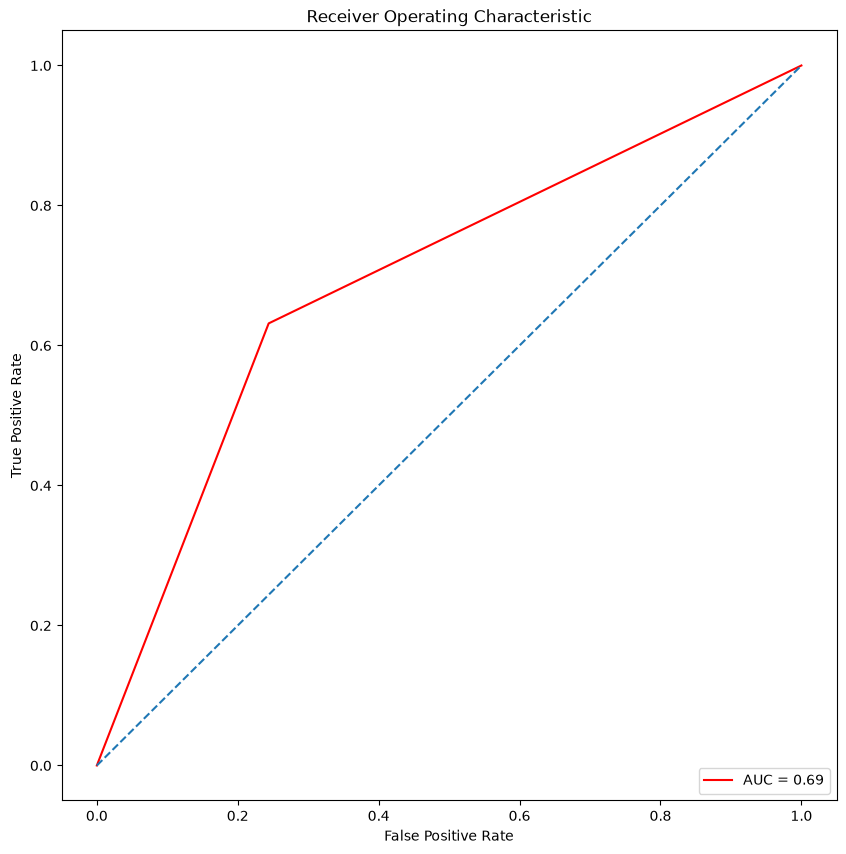

In [27]:
false_positive_rate, true_positive_rate, thresholds = roc_curve(y_test, y_pred)
auc_roc = roc_auc_score(y_test, y_pred, average='weighted')
plt.figure(figsize=(10,10))
plt.title('Receiver Operating Characteristic')
plt.plot(false_positive_rate,true_positive_rate, color='red',label = 'AUC = %0.2f' % auc_roc)
plt.legend(loc = 'lower right')
plt.plot([0, 1], [0, 1],linestyle='--')
plt.axis('tight')
plt.ylabel('True Positive Rate')
plt.xlabel('False Positive Rate')

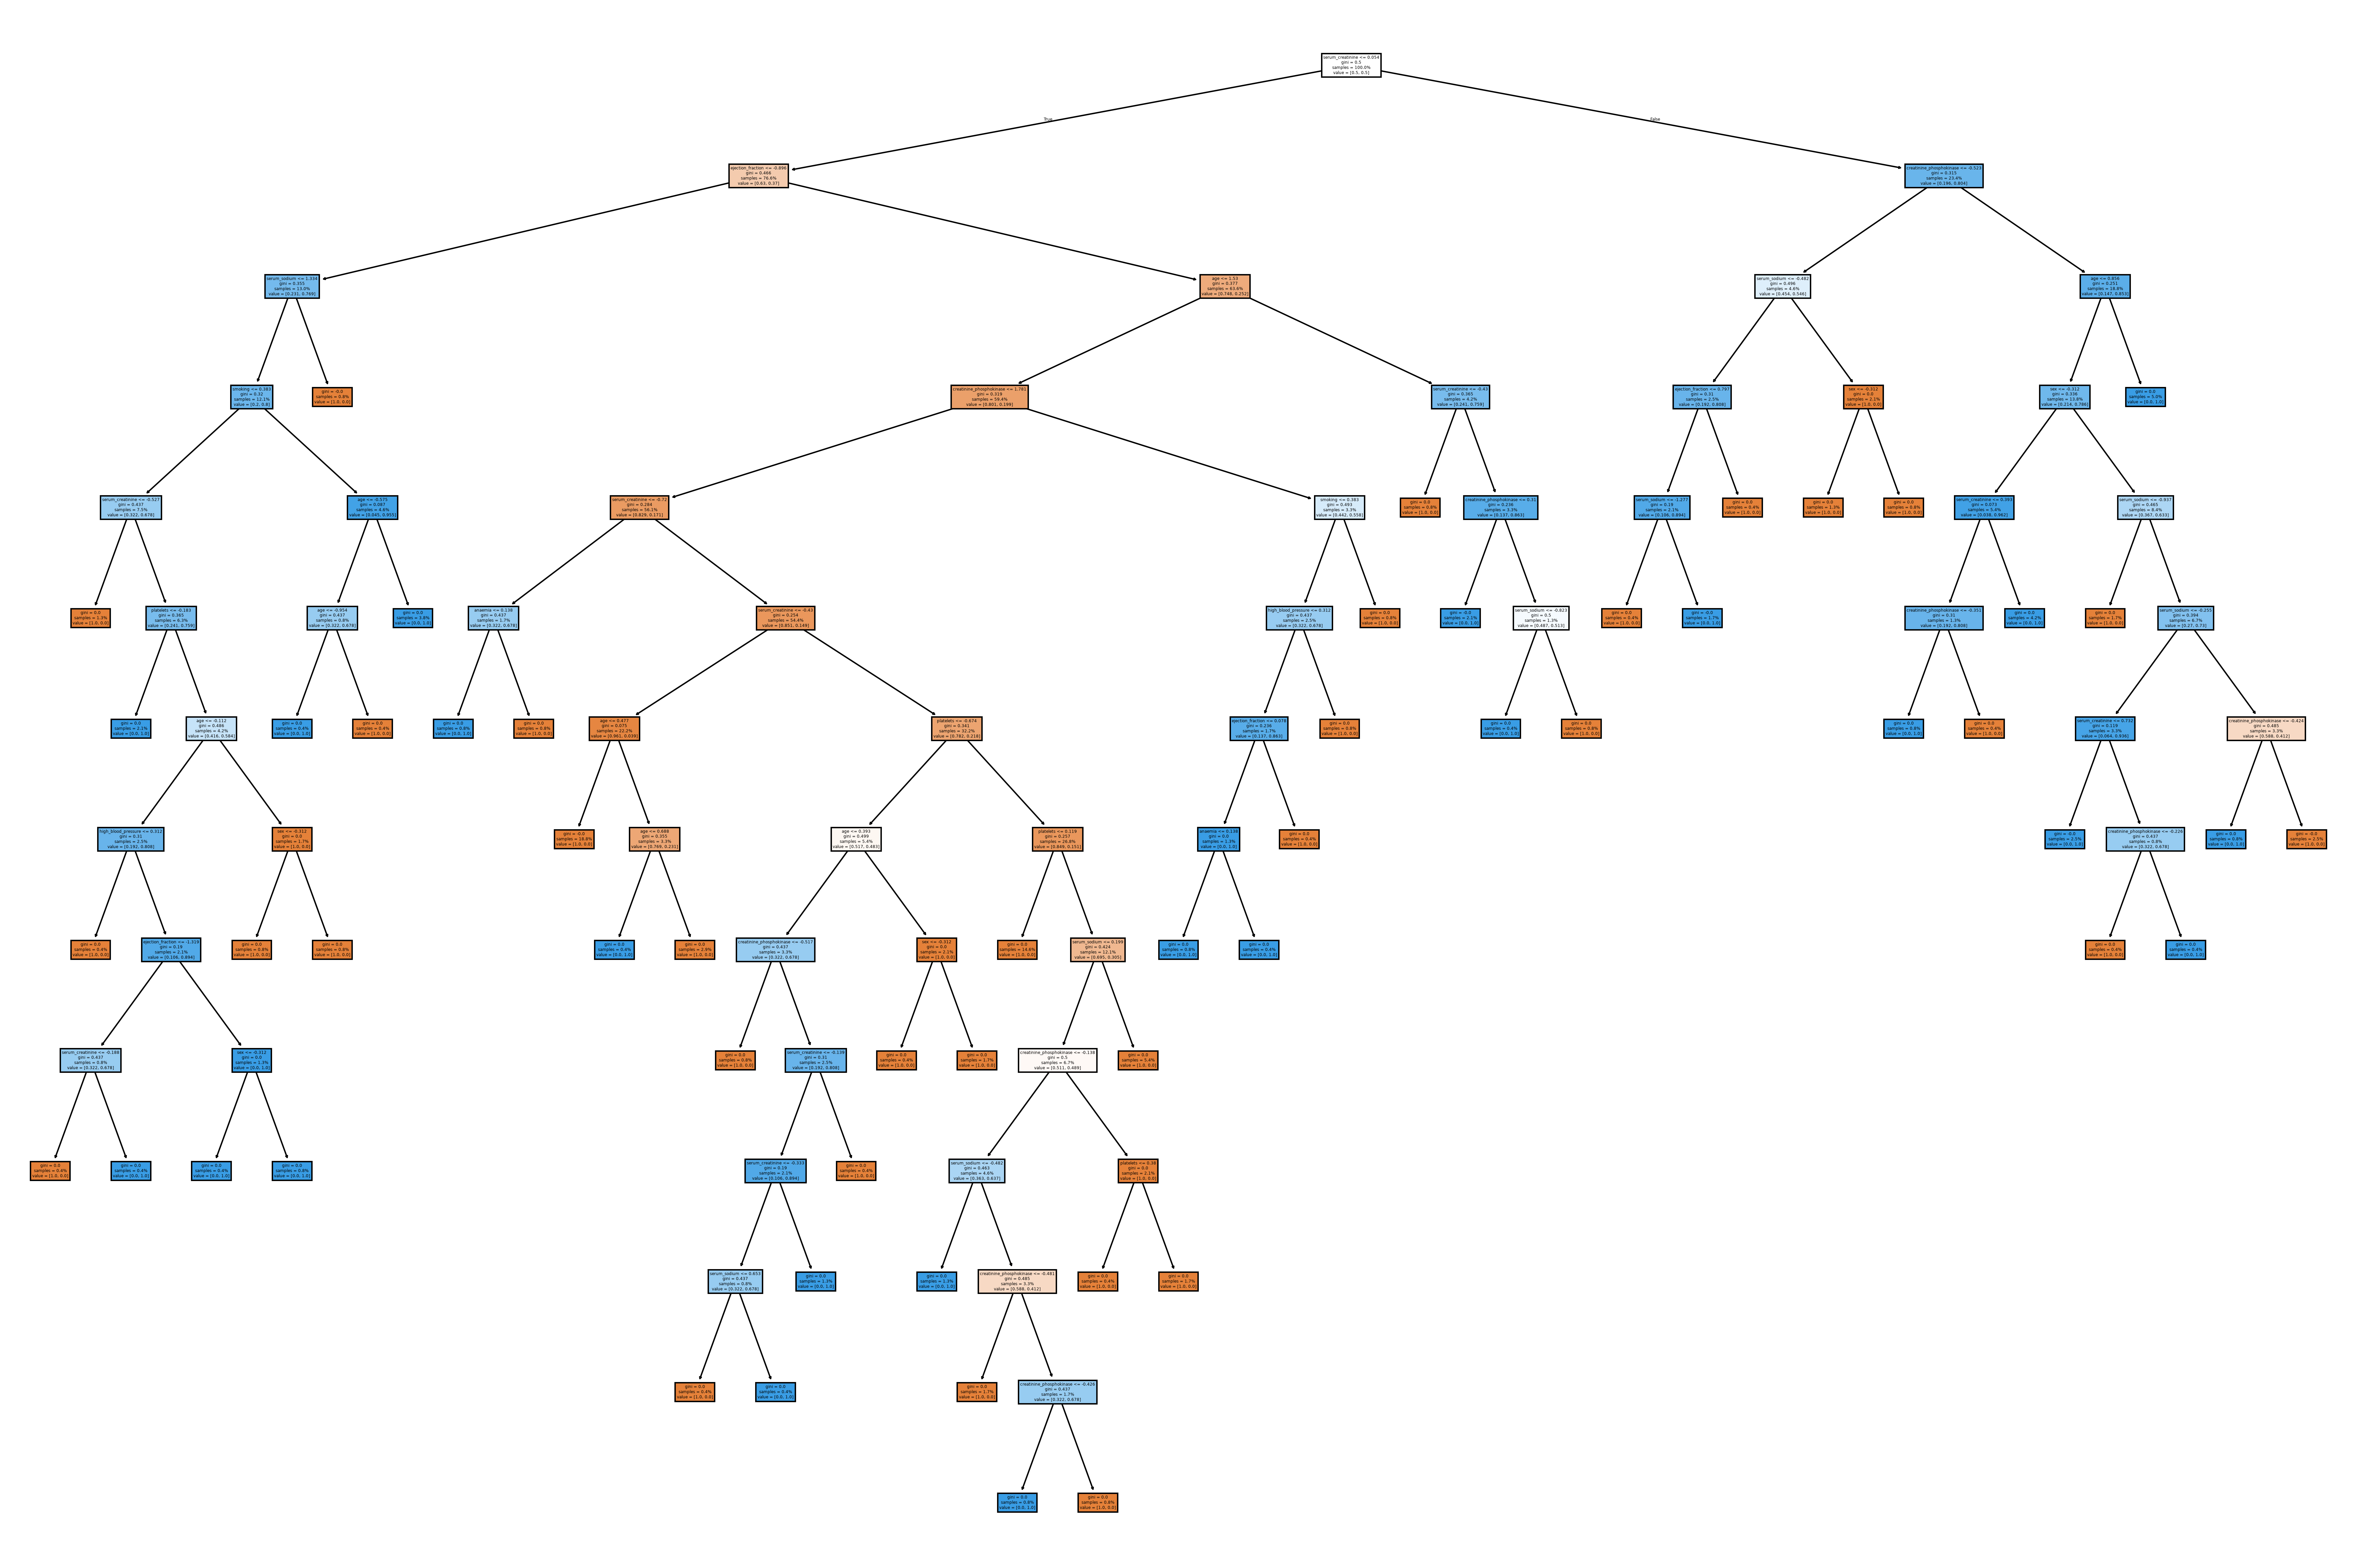

In [28]:
plt.figure(figsize=(30, 20), dpi=300)
tree.plot_tree(tree_model.best_estimator_, proportion=True, filled=True, feature_names=data_set.iloc[:,0:11].columns)
plt.show()
